In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Environment is ready!")
print("Pandas version:", pd.__version__)

Environment is ready!
Pandas version: 3.0.5


In [3]:
df = pd.read_csv("../data/raw/marketing_campaign.csv", sep="\t")

In [4]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [5]:
df.shape

(2240, 29)

In [6]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response'],
      dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

In [8]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64

In [9]:
#The percentage of missing values in Income column
df["Income"].isnull().mean() * 100

np.float64(1.0714285714285714)

In [10]:
# Display the first 5 values from the Dt_Customer column
df["Dt_Customer"].head()

0    04-09-2012
1    08-03-2014
2    21-08-2013
3    10-02-2014
4    19-01-2014
Name: Dt_Customer, dtype: str

In [11]:
# Convert the Dt_Customer column from text to datetime format
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"],format="%d-%m-%Y")

In [12]:
# Check the data type after conversion
df["Dt_Customer"].dtype

dtype('<M8[us]')

In [13]:
# Count missing values in the Dt_Customer column
df["Dt_Customer"].isnull().sum()

np.int64(0)

In [14]:
# Find the earliest customer registration date
df["Dt_Customer"].min()

Timestamp('2012-07-30 00:00:00')

In [15]:
# Find the latest customer registration date
df["Dt_Customer"].max()

Timestamp('2014-06-29 00:00:00')

In [16]:
# Display descriptive statistics for all numerical columns
df.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,2013-07-10 10:01:42.857142,49.109375,303.935714,26.302232,166.950000,...,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,2012-07-30 00:00:00,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,2013-01-16 00:00:00,24.000000,23.750000,1.000000,16.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,2013-07-08 12:00:00,49.000000,173.500000,8.000000,67.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,2013-12-30 06:00:00,74.000000,504.250000,33.000000,232.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,2014-06-29 00:00:00,99.000000,1493.000000,199.000000,1725.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,NaN,28.962453,336.597393,39.773434,225.715373,...,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274


In [17]:
# Calculate customer age using 2014 as the reference year
df["Age"] = 2014 - df["Year_Birth"]
# Display descriptive statistics for customer age
df["Age"].describe()

count    2240.000000
mean       45.194196
std        11.984069
min        18.000000
25%        37.000000
50%        44.000000
75%        55.000000
max       121.000000
Name: Age, dtype: float64

In [18]:
df[df["Age"] > 100][["ID","Year_Birth", "Age"]]

,ID,Year_Birth,Age
192,7829,1900,114
239,11004,1893,121
339,1150,1899,115


In [19]:
# Display customers younger than 18 years
df[df["Age"] < 18][["ID", "Year_Birth", "Age"]]

,ID,Year_Birth,Age


In [20]:
df.loc[df["Age"] > 100]

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age
192,7829,1900,2n Cycle,Divorced,36640.0,1,0,2013-09-26,99,15,...,0,0,0,0,0,1,3,11,0,114
239,11004,1893,2n Cycle,Single,60182.0,0,1,2014-05-17,23,8,...,0,0,0,0,0,0,3,11,0,121
339,1150,1899,PhD,Together,83532.0,0,0,2013-09-26,36,755,...,0,0,1,0,0,0,3,11,0,115


In [21]:
# Compare the income and household information of customers older than 100
df.loc[
    df["Age"] > 100,
    ["ID", "Year_Birth", "Age", "Income",
     "Education", "Marital_Status", "Kidhome", "Teenhome"]
]

,ID,Year_Birth,Age,Income,Education,Marital_Status,Kidhome,Teenhome
192,7829,1900,114,36640.0,2n Cycle,Divorced,1,0
239,11004,1893,121,60182.0,2n Cycle,Single,0,1
339,1150,1899,115,83532.0,PhD,Together,0,0


In [22]:
# Flag customers older than 100 for further investigation
df["Age Outliers"] = df["Age"] > 100

In [23]:
# Store customers older than 100 in a separate DataFrame
df_age_outliers = df.loc[df["Age"] > 100].copy()

# Create the cleaned dataset for further analysis
df_clean = df.loc[df["Age"] <= 100].copy()

# Store customers with income above 200,000 separately
df_income_outliers = df_clean.loc[
    df_clean["Income"] > 200000
].copy()

# Exclude extreme income values while retaining missing income values
df_clean = df_clean.loc[
    (df_clean["Income"] <= 200000) |
    (df_clean["Income"].isnull())
].copy()

# Compare the number of records in each DataFrame
print("Original dataset:", df.shape)
print("Age outliers:", df_age_outliers.shape)
print("Cleaned dataset:", df_clean.shape)

Original dataset: (2240, 31)
Age outliers: (3, 31)
Cleaned dataset: (2236, 31)


In [24]:
# Save the cleaned dataset to a CSV file
df_clean.to_csv("../data/cleaned_data.csv", index=False)

In [25]:
df_clean.shape

(2236, 31)

In [26]:
#Calculate the median customer income
df_clean["Income"].median()

np.float64(51371.0)

In [27]:
#Calculate the mean customer income
df_clean["Income"].mean()

np.float64(51958.81057866185)

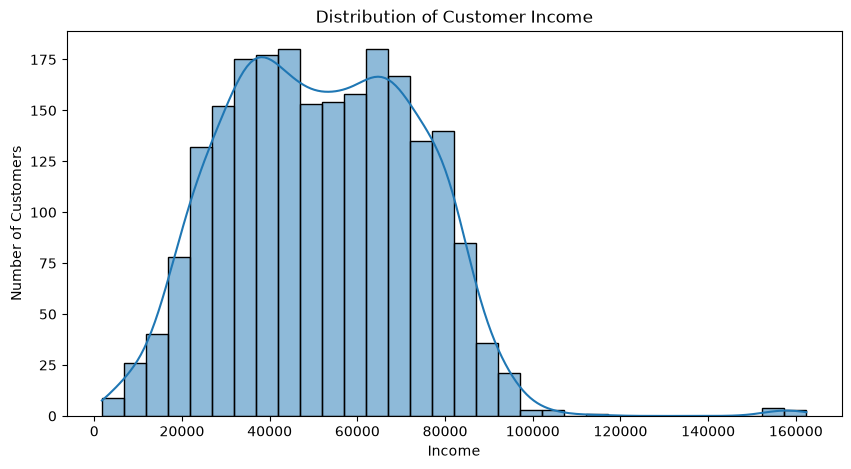

In [28]:
# Create a histogram to visualise customer income distribution
plt.figure(figsize=(10, 5))
sns.histplot(data=df_clean, x="Income", kde=True)

# Add chart title and axis labels
plt.title("Distribution of Customer Income")
plt.xlabel("Income")
plt.ylabel("Number of Customers")

# Display the chart
plt.show()

In [29]:
# Display customers with income higher than 150,000
df_clean.loc[df_clean["Income"]> 150000,["ID","Year_Birth","Age","Income"]]

,ID,Year_Birth,Age,Income
164,8475,1973,41,157243.0
617,1503,1976,38,162397.0
655,5555,1975,39,153924.0
687,1501,1982,32,160803.0
1300,5336,1971,43,157733.0
1653,4931,1977,37,157146.0
2132,11181,1949,65,156924.0


In [30]:
# Display the 10 customers with the highest income
df_clean.nlargest(10, "Income")[["ID","Year_Birth","Age","Income"]]

,ID,Year_Birth,Age,Income
617,1503,1976,38,162397.0
687,1501,1982,32,160803.0
1300,5336,1971,43,157733.0
164,8475,1973,41,157243.0
1653,4931,1977,37,157146.0
2132,11181,1949,65,156924.0
655,5555,1975,39,153924.0
1898,4619,1945,69,113734.0
646,4611,1970,44,105471.0
252,10089,1974,40,102692.0


In [31]:
# Identify customers with missing income in the original DataFrame
df_clean.loc[
    df_clean["Income"].isnull(),
    ["ID", "Year_Birth", "Age", "Income"]
]

,ID,Year_Birth,Age,Income
10,1994,1983,31,NaN
27,5255,1986,28,NaN
43,7281,1959,55,NaN
48,7244,1951,63,NaN
58,8557,1982,32,NaN
71,10629,1973,41,NaN
90,8996,1957,57,NaN
91,9235,1957,57,NaN
92,5798,1973,41,NaN
128,8268,1961,53,NaN


In [32]:
median_income = df_clean["Income"].median()
print("Median income:",median_income)

Median income: 51371.0


In [33]:
# Replace missing income values with the median income
df_clean["Income"] = df_clean["Income"].fillna(median_income)

In [34]:
# Count missing values in the Income column after imputation
print("Missing income values:", df_clean["Income"].isnull().sum())

# Display the updated number of records
print("Working dataset:", df_clean.shape)

Missing income values: 0
Working dataset: (2236, 31)


In [35]:
# Count missing values in every column
missing_values = df_clean.isnull().sum()

# Display only columns that contain missing values
missing_values[missing_values > 0]

Series([], dtype: int64)

In [36]:
# Count duplicate rows in the cleaned dataset
print("Duplicate rows:", df_clean.duplicated().sum())

Duplicate rows: 0


In [37]:
# Display column names and their data types
df_clean.info()

<class 'pandas.DataFrame'>
Index: 2236 entries, 0 to 2239
Data columns (total 31 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   ID                   2236 non-null   int64         
 1   Year_Birth           2236 non-null   int64         
 2   Education            2236 non-null   str           
 3   Marital_Status       2236 non-null   str           
 4   Income               2236 non-null   float64       
 5   Kidhome              2236 non-null   int64         
 6   Teenhome             2236 non-null   int64         
 7   Dt_Customer          2236 non-null   datetime64[us]
 8   Recency              2236 non-null   int64         
 9   MntWines             2236 non-null   int64         
 10  MntFruits            2236 non-null   int64         
 11  MntMeatProducts      2236 non-null   int64         
 12  MntFishProducts      2236 non-null   int64         
 13  MntSweetProducts     2236 non-null   int64       

In [38]:
# Save the final cleaned dataset to a CSV file
df_clean.to_csv("../data/cleaned_data.csv", index=False)

Exploratory Data Analysis                                                    

Customer Demographics

In [39]:
# Calculate descriptive statistics for customer age
df_clean["Age"].describe()

count    2236.000000
mean       45.101968
std        11.703281
min        18.000000
25%        37.000000
50%        44.000000
75%        55.000000
max        74.000000
Name: Age, dtype: float64

In [40]:
# Calculate the average customer age
mean_age = df_clean["Age"].mean()

# Calculate the median customer age
median_age = df_clean["Age"].median()

# Display both values
print("Average customer age:", round(mean_age, 2))
print("Median customer age:", median_age)

Average customer age: 45.1
Median customer age: 44.0


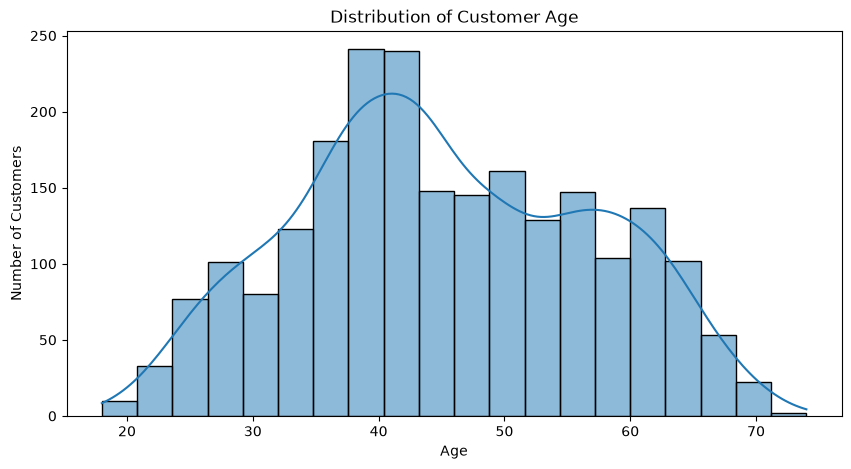

In [41]:
# Create a histogram to visualise customer age distribution
plt.figure(figsize=(10, 5))
sns.histplot(data=df_clean, x="Age", bins=20, kde=True)

# Add chart title and axis labels
plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

# Display the chart
plt.show()

In [42]:
# Define age groups using customer age
age_bins = [18,25,35,45,55,65,75,85,95,105]

# Assign each customer to an age group
df_clean["Age Group"] = pd.cut(df_clean["Age"],bins=age_bins,right=False)

#Count customers in each age froup
age_group_count = df_clean["Age Group"].value_counts().sort_index()

#Dislay the number of customers in each age group
print(age_group_count)

Age Group
[18, 25)      61
[25, 35)     363
[35, 45)     739
[45, 55)     506
[55, 65)     460
[65, 75)     107
[75, 85)       0
[85, 95)       0
[95, 105)      0
Name: count, dtype: int64


In [43]:
#The analysis shows that customers aged 35–44 represent the largest age segment,
#accounting for approximately one-third of the customer base. Customers aged 45–64 
#also represent a substantial proportion, suggesting that middle-aged adults form the core customer demographic.

In [44]:
#Count the customers in each education category
education_count = df_clean["Education"].value_counts()

#Display the number of customers in each category
print(education_count)

Education
Graduation    1126
PhD            485
Master         370
2n Cycle       201
Basic           54
Name: count, dtype: int64


In [45]:
#Most of our customers have a Graduation-level education, making up about 50% of the customer base.
#Another 38% have either a Master's or PhD degree.
#This suggests that most of our customers have a relatively high level of education.

In [46]:
#Count customers in each marital status category
marital_status_count = df_clean["Marital_Status"].value_counts()

#Display the number of customers in each marital status category
print(marital_status_count)

Marital_Status
Married     864
Together    578
Single      479
Divorced    231
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64


In [47]:
# Replace unclear marital status categories with "Unknown"
df_clean["Marital_Status"] = df_clean["Marital_Status"].replace(["Alone","Absurd","YOLO"],"Unknown")



In [48]:
#Check the count of customers of each Marital status category to varify the changes
marital_status_count = df_clean["Marital_Status"].value_counts()
print(marital_status_count)

Marital_Status
Married     864
Together    578
Single      479
Divorced    231
Widow        77
Unknown       7
Name: count, dtype: int64


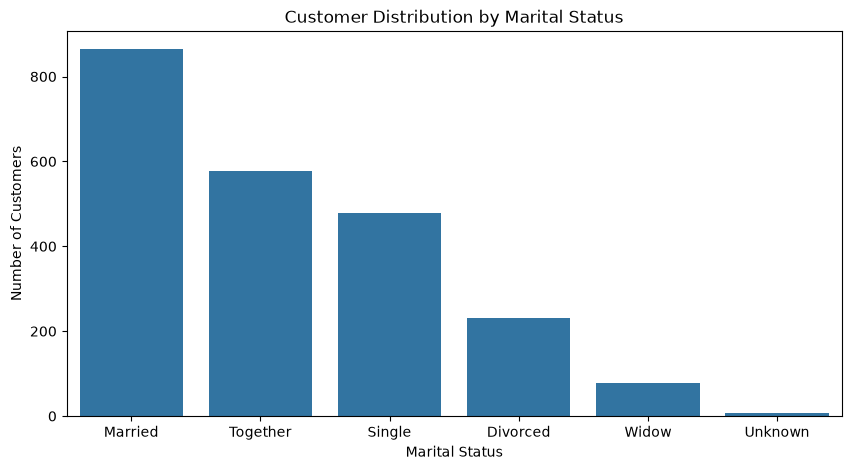

In [49]:
# Create a bar chart showing customer marital status
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_clean,
    x="Marital_Status",
    order=df_clean["Marital_Status"].value_counts().index
)

# Add chart title and axis labels
plt.title("Customer Distribution by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Number of Customers")

# Display the chart
plt.show()

In [50]:
#Most customers are either married or living with a partner, representing approximately 64.5% of the customer base. 
#Married is the most common category, accounting for around 38.6% of customers. 
#Single and Divorced customers together make up approximately 31.8%.
#The smallest groups are Widow and Unknown.

In [51]:
# Count customers by number of young children at home
print(df_clean["Kidhome"].value_counts().sort_index())

# Count customers by number of teenagers at home
print(df_clean["Teenhome"].value_counts().sort_index())

Kidhome
0    1291
1     897
2      48
Name: count, dtype: int64
Teenhome
0    1155
1    1029
2      52
Name: count, dtype: int64


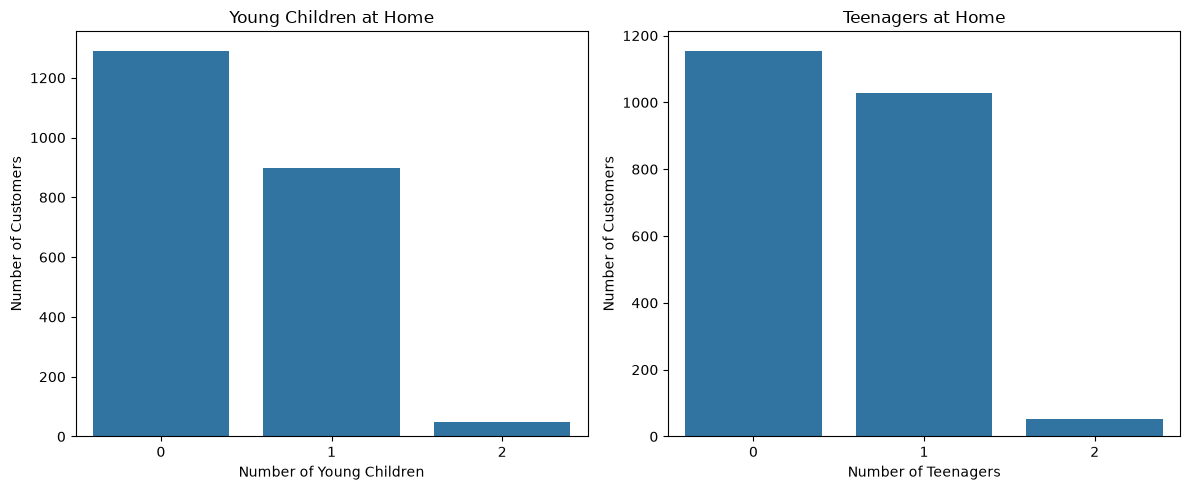

In [52]:
# Create two side-by-side charts for household composition
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Visualise the number of young children at home
sns.countplot(data=df_clean, x="Kidhome", ax=axes[0])
axes[0].set_title("Young Children at Home")
axes[0].set_xlabel("Number of Young Children")
axes[0].set_ylabel("Number of Customers")

# Visualise the number of teenagers at home
sns.countplot(data=df_clean, x="Teenhome", ax=axes[1])
axes[1].set_title("Teenagers at Home")
axes[1].set_xlabel("Number of Teenagers")
axes[1].set_ylabel("Number of Customers")

# Adjust spacing between the charts
plt.tight_layout()

# Display both charts
plt.show()

In [53]:
#Most customers do not have young children or teenagers living at home.
#However, a considerable number have one child or one teenager.
#Only a small proportion of customers have two children or two teenagers in their household.

Customer purchasing behaviour

In [54]:
#Calculate product spending for each product category
product_spending = df_clean[[ 
        "MntWines",
        "MntFruits",
        "MntMeatProducts",
        "MntFishProducts",
        "MntSweetProducts",
        "MntGoldProds"]].sum()

#Sort product categories by total spending
product_spending = product_spending.sort_values(ascending=False)

#Display total spending by category
print(product_spending)

MntWines            680029
MntMeatProducts     373375
MntGoldProds         98346
MntFishProducts      83931
MntSweetProducts     60552
MntFruits            58753
dtype: int64


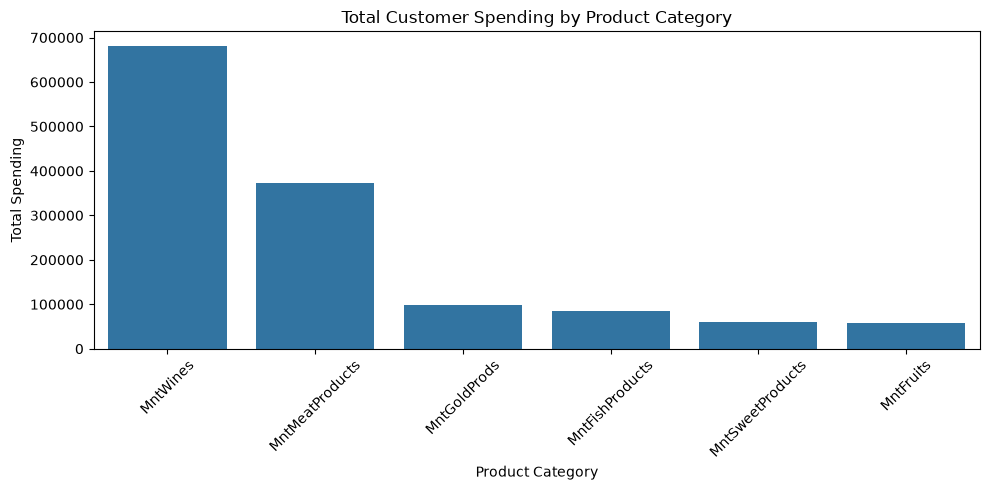

In [55]:
# Create a bar chart showing total spending by product category
plt.figure(figsize=(10, 5))

sns.barplot(
    x=product_spending.index,
    y=product_spending.values
)

# Add chart title and axis labels
plt.title("Total Customer Spending by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Spending")

# Rotate category labels for better readability
plt.xticks(rotation=45)

# Display the chart
plt.tight_layout()
plt.show()

In [56]:
#Customers spend the most on wines, followed by meat products.
#Spending on these two categories is significantly higher than on the other product categories.
#Fruits and sweet products receive the lowest overall spending.

In [57]:
# Calculate average spending per customer for each product category
average_spending = df_clean[
    [
        "MntWines",
        "MntFruits",
        "MntMeatProducts",
        "MntFishProducts",
        "MntSweetProducts",
        "MntGoldProds"
    ]
].mean()

# Sort product categories from highest to lowest average spending
average_spending = average_spending.sort_values(ascending=False)

# Display average spending by product category
print(average_spending.round(2))

MntWines            304.13
MntMeatProducts     166.98
MntGoldProds         43.98
MntFishProducts      37.54
MntSweetProducts     27.08
MntFruits            26.28
dtype: float64


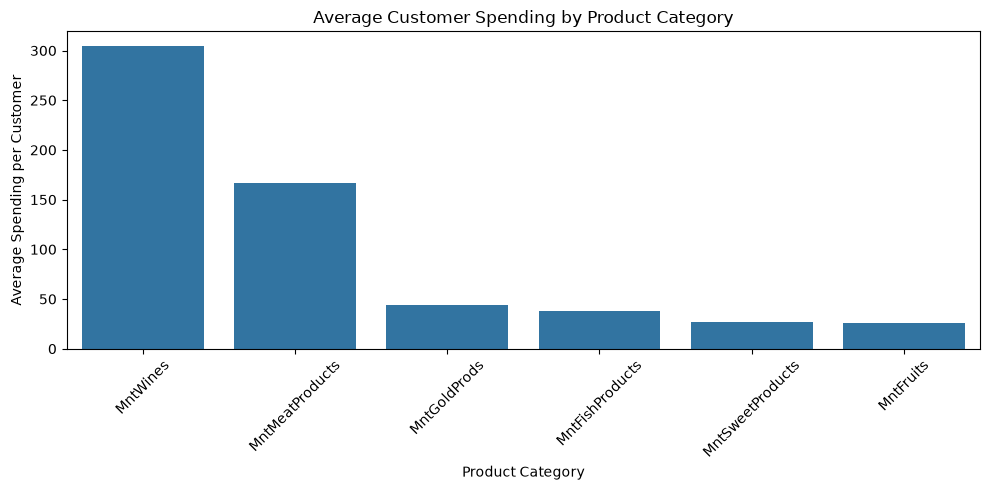

In [58]:
# Create a bar chart showing average spending per customer
plt.figure(figsize=(10, 5))

sns.barplot(
    x=average_spending.index,
    y=average_spending.values
)

# Add chart title and axis labels
plt.title("Average Customer Spending by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Spending per Customer")

# Rotate category labels for better readability
plt.xticks(rotation=45)

# Display the chart
plt.tight_layout()
plt.show()

In [59]:
#Customers spend the most on wines, with an average of 304 per customer, followed by meat products at around 167.
#Spending on the remaining product categories is considerably lower. 
#This suggests that wines and meat products are the most important product categories in terms of customer spending.

In [60]:
# Define the product spending columns
spending_columns = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

# Calculate total spending for each customer
df_clean["Total_Spending"] = df_clean[spending_columns].sum(axis=1)

# Display the first five customers and their total spending
df_clean[["ID", "Total_Spending"]].head()

,ID,Total_Spending
0,5524,1617
1,2174,27
2,4141,776
3,6182,53
4,5324,422


In [61]:
# Calculate descriptive statistics for total customer spending
df_clean["Total_Spending"].describe()

count    2236.000000
mean      605.986583
std       601.865156
min         5.000000
25%        69.000000
50%       396.500000
75%      1045.500000
max      2525.000000
Name: Total_Spending, dtype: float64

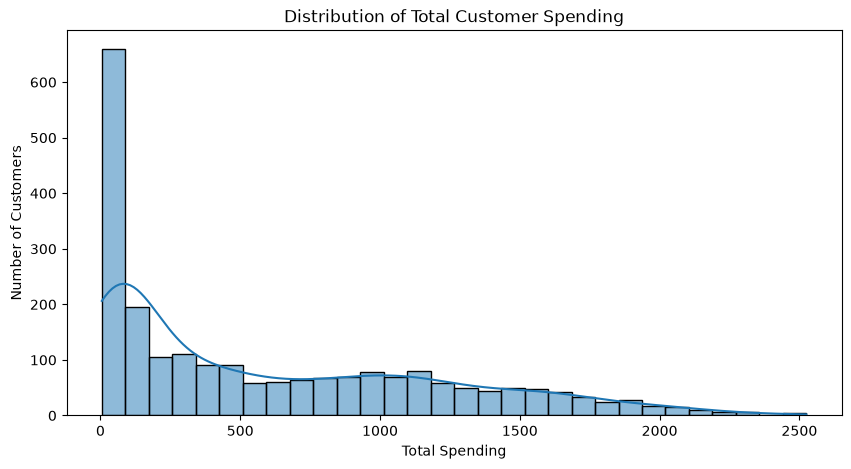

In [62]:
# Create a histogram showing the distribution of total customer spending
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="Total_Spending",
    bins=30,
    kde=True
)

# Add chart title and axis labels
plt.title("Distribution of Total Customer Spending")
plt.xlabel("Total Spending")
plt.ylabel("Number of Customers")

# Display the chart
plt.show()

In [63]:
#Most customers spend between 0 and 500 on products, although a considerable number spend between 500 and 1,500.
#Only a small proportion of customers spend more than 2,000. 
#Overall, the distribution is right-skewed, suggesting that high-spending customers are relatively uncommon.

In [64]:
# Display the 10 customers with the highest total spending
top_customers = df_clean.nlargest(10, "Total_Spending")[
    ["ID", "Age", "Income", "Total_Spending"]
]

# Display the results
print(top_customers)

         ID  Age   Income  Total_Spending
1179   5735   23  90638.0            2525
1572   5350   23  90638.0            2525
1492   1763   26  87679.0            2524
987    4580   45  75759.0            2486
1052   4475   65  69098.0            2440
1601   5453   58  90226.0            2352
1458  10133   44  93790.0            2349
1288   9010   42  83151.0            2346
943    5386   61  94384.0            2302
1301   6024   61  94384.0            2302


In [65]:
# Calculate the correlation between customer income and total spending
income_spending_corr = df_clean["Income"].corr(df_clean["Total_Spending"])

# Display the correlation coefficient
print("Income-Spending Correlation:", round(income_spending_corr, 3))

Income-Spending Correlation: 0.789


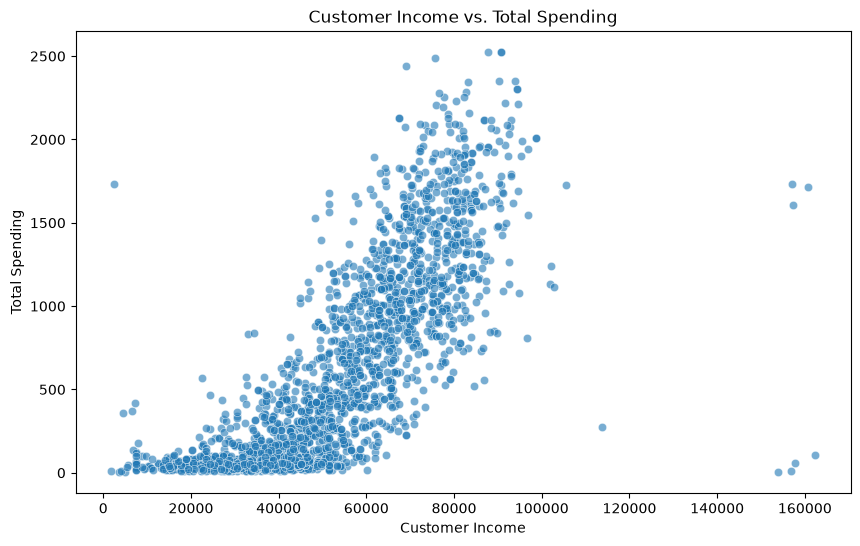

In [66]:
# Create a scatter plot to examine the relationship between income and spending
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="Income",
    y="Total_Spending",
    alpha=0.6
)

# Add chart title and axis labels
plt.title("Customer Income vs. Total Spending")
plt.xlabel("Customer Income")
plt.ylabel("Total Spending")

# Display the chart
plt.show()

In [67]:
#The scatter plot confirms a strong positive relationship between income and customer spending. 
#Customers with higher incomes generally tend to spend more, although there are some exceptions. 
#This suggests that income is an important factor associated with purchasing behaviour,
#but it does not fully explain how much each customer spends.

In [68]:
# Calculate total purchases for each purchasing channel
channel_purchases = df_clean[
    [
        "NumWebPurchases",
        "NumCatalogPurchases",
        "NumStorePurchases"
    ]
].sum()

# Sort purchasing channels from highest to lowest
channel_purchases = channel_purchases.sort_values(ascending=False)

# Display total purchases by channel
print(channel_purchases)

NumStorePurchases      12959
NumWebPurchases         9140
NumCatalogPurchases     5955
dtype: int64


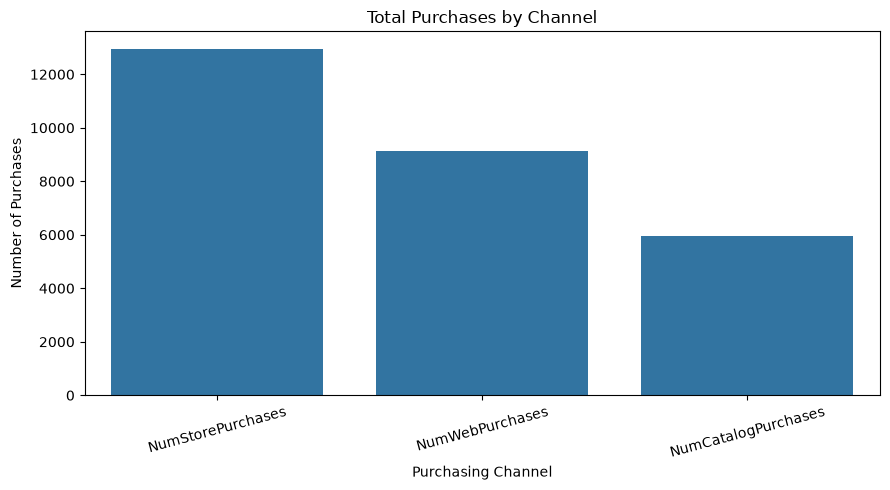

In [69]:
# Create a bar chart showing purchases by channel
plt.figure(figsize=(9, 5))

sns.barplot(
    x=channel_purchases.index,
    y=channel_purchases.values
)

# Add chart title and axis labels
plt.title("Total Purchases by Channel")
plt.xlabel("Purchasing Channel")
plt.ylabel("Number of Purchases")

# Improve the chart layout
plt.xticks(rotation=15)
plt.tight_layout()

# Display the chart
plt.show()

In [70]:
#Customers make most of their purchases in physical stores, followed by online purchases through the website. 
#Catalogue purchases are the least common.
#This suggests that customers still prefer shopping in physical stores, although online shopping is also an important purchasing channel.

Household Composition vs. Purchasing Channels
Does having children at home influence which purchasing channels customers use?

In [71]:
# Calculate average purchases by channel for each number of young children
kidhome_channels = df_clean.groupby("Kidhome")[
    [
        "NumWebPurchases",
        "NumCatalogPurchases",
        "NumStorePurchases"
    ]
].mean()

# Display the results
print(kidhome_channels.round(2))

         NumWebPurchases  NumCatalogPurchases  NumStorePurchases
Kidhome                                                         
0                   4.98                 3.96               7.22
1                   2.88                 0.90               3.87
2                   2.79                 0.71               3.44


In [72]:
#Customers without young children at home make more purchases across all channels. 
#Physical stores are the most frequently used purchasing channel regardless of household composition. 
#Customers with one or two children have lower average purchasing activity, particularly through catalogues.

In [73]:
# Calculate average purchases by channel for each number of teenagers
teenhome_channels = df_clean.groupby("Teenhome")[
    [
        "NumWebPurchases",
        "NumCatalogPurchases",
        "NumStorePurchases"
    ]
].mean()

# Display the results
print(teenhome_channels.round(2))

          NumWebPurchases  NumCatalogPurchases  NumStorePurchases
Teenhome                                                         
0                    3.66                 2.99               5.64
1                    4.53                 2.31               5.94
2                    4.79                 2.40               6.25


In [74]:
#Physical stores are the most frequently used purchasing channel regardless of whether customers have teenagers at home. 
#Customers with teenagers tend to make more purchases overall, particularly through the website and physical stores. 
#This suggests that household composition may be associated with different purchasing patterns.

In [75]:
df_clean.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,...,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Total_Spending
count,2236.000000,2236.000000,2236.000000,2236.000000,2236.000000,2236,2236.000000,2236.00000,2236.000000,2236.000000,...,2236.000000,2236.000000,2236.000000,2236.000000,2236.000000,2236.0,2236.0,2236.000000,2236.000000,2236.000000
mean,5589.008497,1968.898032,51952.501342,0.444097,0.506708,2013-07-10 05:26:30.697674,49.116279,304.12746,26.275939,166.983453,...,0.074687,0.072451,0.064401,0.013417,0.008945,3.0,11.0,0.149374,45.101968,605.986583
min,0.000000,1940.000000,1730.000000,0.000000,0.000000,2012-07-30 00:00:00,0.000000,0.00000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000,18.000000,5.000000
25%,2828.250000,1959.000000,35502.500000,0.000000,0.000000,2013-01-16 00:00:00,24.000000,24.00000,1.000000,16.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000,37.000000,69.000000
50%,5454.500000,1970.000000,51371.000000,0.000000,0.000000,2013-07-08 00:00:00,49.000000,174.00000,8.000000,67.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000,44.000000,396.500000
75%,8421.750000,1977.000000,68275.750000,1.000000,1.000000,2013-12-30 06:00:00,74.000000,504.25000,33.000000,232.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000,55.000000,1045.500000
max,11191.000000,1996.000000,162397.000000,2.000000,2.000000,2014-06-29 00:00:00,99.000000,1493.00000,199.000000,1725.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000,74.000000,2525.000000
std,3244.826887,11.703281,21411.469885,0.538459,0.544609,NaN,28.957284,336.59181,39.724007,225.689645,...,0.262944,0.259291,0.245520,0.115077,0.094173,0.0,0.0,0.356536,11.703281,601.865156


In [76]:
# Display the data types of all columns in the working DataFrame
print(df_clean.dtypes)

ID                              int64
Year_Birth                      int64
Education                         str
Marital_Status                    str
Income                        float64
Kidhome                         int64
Teenhome                        int64
Dt_Customer            datetime64[us]
Recency                         int64
MntWines                        int64
MntFruits                       int64
MntMeatProducts                 int64
MntFishProducts                 int64
MntSweetProducts                int64
MntGoldProds                    int64
NumDealsPurchases               int64
NumWebPurchases                 int64
NumCatalogPurchases             int64
NumStorePurchases               int64
NumWebVisitsMonth               int64
AcceptedCmp3                    int64
AcceptedCmp4                    int64
AcceptedCmp5                    int64
AcceptedCmp1                    int64
AcceptedCmp2                    int64
Complain                        int64
Z_CostContac

In [77]:
# Define the marketing campaign columns
campaign_columns = [
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "Response"
]

# Calculate the number of customers who accepted each campaign
campaign_acceptance = df_clean[campaign_columns].sum()

# Display the acceptance counts
print(campaign_acceptance)

AcceptedCmp1    144
AcceptedCmp2     30
AcceptedCmp3    163
AcceptedCmp4    167
AcceptedCmp5    162
Response        334
dtype: int64


In [78]:
#Among the five previous campaigns, Campaign 4 had the highest number of acceptances, while Campaign 2 had the lowest.
#The latest campaign received 334 acceptances, making it the most successful in terms of the number of customers who responded positively.

In [79]:
# Calculate the acceptance rate for each marketing campaign
campaign_acceptance_rate = (
    df_clean[campaign_columns].mean() * 100
)

# Sort campaigns from highest to lowest acceptance rate
campaign_acceptance_rate = campaign_acceptance_rate.sort_values(
    ascending=False
)

# Display acceptance rates rounded to two decimal places
print(campaign_acceptance_rate.round(2))

Response        14.94
AcceptedCmp4     7.47
AcceptedCmp3     7.29
AcceptedCmp5     7.25
AcceptedCmp1     6.44
AcceptedCmp2     1.34
dtype: float64


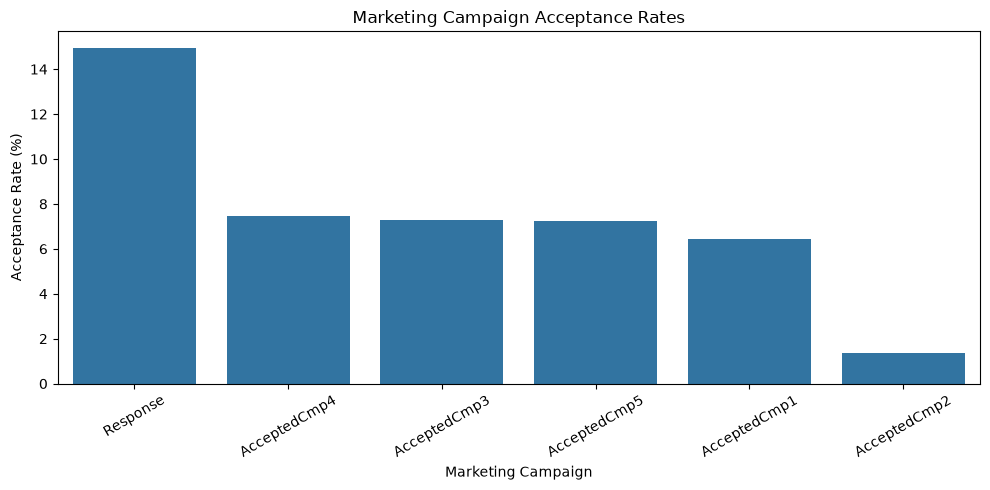

In [80]:
# Create a bar chart showing campaign acceptance rates
plt.figure(figsize=(10, 5))

sns.barplot(
    x=campaign_acceptance_rate.index,
    y=campaign_acceptance_rate.values
)

# Add chart title and axis labels
plt.title("Marketing Campaign Acceptance Rates")
plt.xlabel("Marketing Campaign")
plt.ylabel("Acceptance Rate (%)")

# Rotate campaign labels for better readability
plt.xticks(rotation=30)

# Display the chart
plt.tight_layout()
plt.show()

In [81]:
#The latest marketing campaign achieved the highest acceptance rate, at almost 15%. Among the previous campaigns, Campaign 4 performed best, 
#while Campaign 2 had the lowest acceptance rate.
#Overall, the latest campaign was considerably more successful at getting customers to respond positively.

In [82]:
# Calculate whether each customer accepted at least one previous campaign
df_clean["Accepted_Previous_Campaign"] = (
    df_clean[
        [
            "AcceptedCmp1",
            "AcceptedCmp2",
            "AcceptedCmp3",
            "AcceptedCmp4",
            "AcceptedCmp5"
        ]
    ].sum(axis=1) > 0
)

# Display the number of customers in each group
print(df_clean["Accepted_Previous_Campaign"].value_counts())

Accepted_Previous_Campaign
False    1774
True      462
Name: count, dtype: int64


In [83]:
# Calculate average income for each campaign acceptance group
income_by_acceptance = df_clean.groupby(
    "Accepted_Previous_Campaign"
)["Income"].mean()

# Display average income rounded to two decimal places
print(income_by_acceptance.round(2))

Accepted_Previous_Campaign
False    48529.61
True     65095.81
Name: Income, dtype: float64


In [ ]:
#Customers with higher average incomes were more likely to accept previous marketing campaigns. 
#Around 79% of customers did not accept any of the five campaigns, while only about 21% accepted at least one.
#This suggests that income may be an important factor when identifying customers who are more responsive to marketing campaigns.

In [84]:
# Calculate the campaign acceptance rate for each age group
age_acceptance = df_clean.groupby("Age Group")[
    "Accepted_Previous_Campaign"
].mean() * 100

# Display acceptance rates rounded to two decimal places
print(age_acceptance.round(2))

Age Group
[18, 25)    31.15
[25, 35)    21.76
[35, 45)    17.19
[45, 55)    20.95
[55, 65)    20.00
[65, 75)    36.45
Name: Accepted_Previous_Campaign, dtype: float64


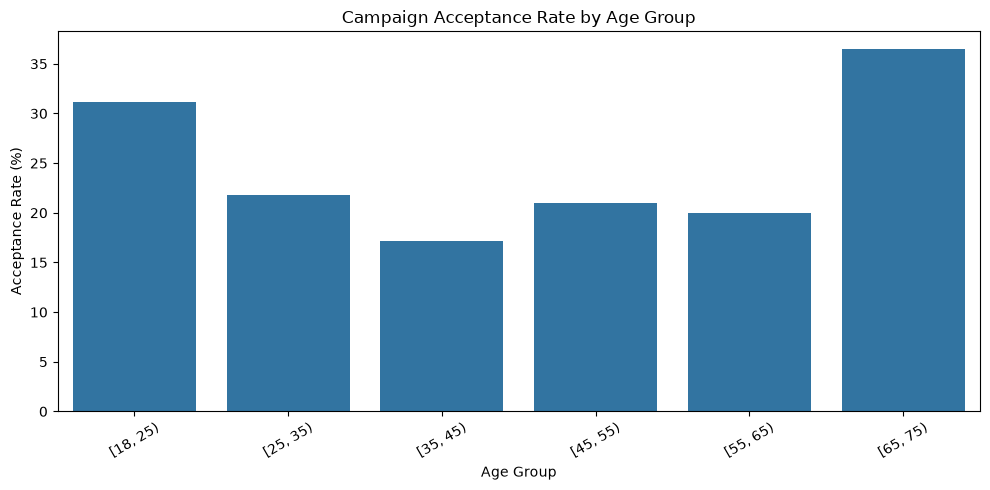

In [85]:
# Create a bar chart showing campaign acceptance rates by age group
plt.figure(figsize=(10, 5))

sns.barplot(
    x=age_acceptance.index.astype(str),
    y=age_acceptance.values
)

# Add chart title and axis labels
plt.title("Campaign Acceptance Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Acceptance Rate (%)")

# Rotate age group labels for better readability
plt.xticks(rotation=30)

# Display the chart
plt.tight_layout()
plt.show()

In [ ]:
#Customers aged 65–75 show the highest response to previous marketing campaigns, with an acceptance rate of 36.45%. 
#Younger customers aged 18–25 also demonstrate relatively high engagement. In contrast, customers aged 35–45 have the lowest acceptance rate. 
#This suggests that age may be an important factor in customer responsiveness to marketing campaigns.

In [86]:
# Calculate campaign acceptance rates by number of young children at home
kidhome_acceptance = df_clean.groupby("Kidhome")[
    "Accepted_Previous_Campaign"
].mean() * 100

# Display acceptance rates rounded to two decimal places
print(kidhome_acceptance.round(2))

Kidhome
0    27.81
1    11.15
2     6.25
Name: Accepted_Previous_Campaign, dtype: float64


In [ ]:
#Customers without young children at home are more likely to accept previous marketing campaigns. 
#The acceptance rate decreases as the number of young children increases, suggesting that household composition may be associated with customer responsiveness.

In [87]:
# Calculate campaign acceptance rates by number of teenagers at home
teenhome_acceptance = df_clean.groupby("Teenhome")[
    "Accepted_Previous_Campaign"
].mean() * 100

# Display acceptance rates rounded to two decimal places
print(teenhome_acceptance.round(2))

Teenhome
0    24.94
1    15.84
2    21.15
Name: Accepted_Previous_Campaign, dtype: float64


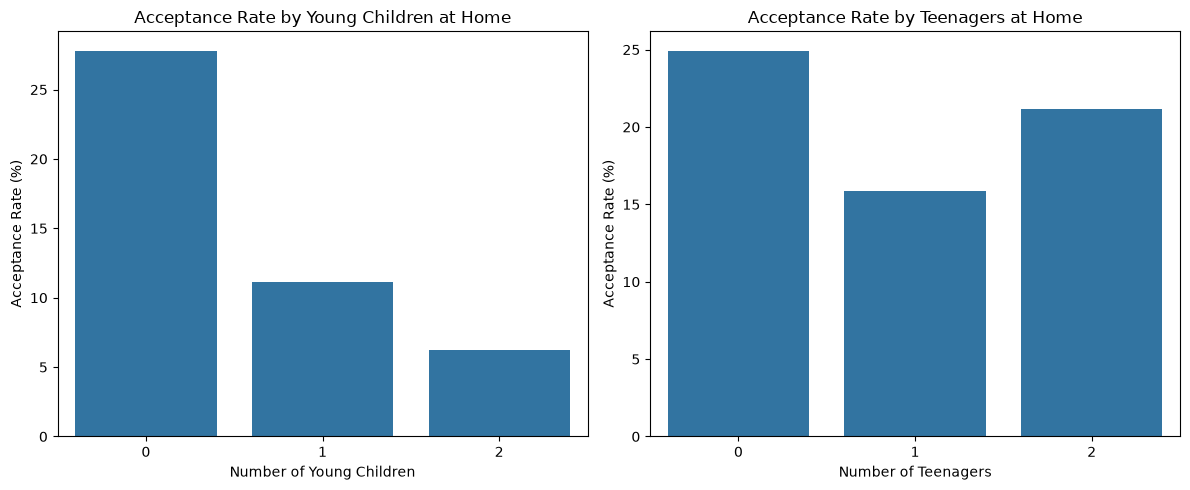

In [88]:
# Create two charts to compare campaign acceptance rates
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot acceptance rates by number of young children
sns.barplot(
    x=kidhome_acceptance.index,
    y=kidhome_acceptance.values,
    ax=axes[0]
)

# Add title and axis labels
axes[0].set_title("Acceptance Rate by Young Children at Home")
axes[0].set_xlabel("Number of Young Children")
axes[0].set_ylabel("Acceptance Rate (%)")

# Plot acceptance rates by number of teenagers
sns.barplot(
    x=teenhome_acceptance.index,
    y=teenhome_acceptance.values,
    ax=axes[1]
)

# Add title and axis labels
axes[1].set_title("Acceptance Rate by Teenagers at Home")
axes[1].set_xlabel("Number of Teenagers")
axes[1].set_ylabel("Acceptance Rate (%)")

# Adjust the layout and display the charts
plt.tight_layout()
plt.show()

In [ ]:
#Customers without teenagers at home are more likely to accept previous marketing campaigns. 
#Customers with two teenagers also show relatively high acceptance, while those with one teenager have the lowest acceptance rate. 
#This suggests that household composition may influence customer responsiveness to marketing campaigns.

In [89]:
# Calculate the overall acceptance rate of the latest marketing campaign
latest_campaign_rate = df_clean["Response"].mean() * 100

# Display the acceptance rate
print("Latest campaign acceptance rate:", round(latest_campaign_rate, 2), "%")

Latest campaign acceptance rate: 14.94 %


In [90]:
# Calculate average income for customers who accepted or rejected the latest campaign
latest_income = df_clean.groupby("Response")["Income"].mean()

# Display average income for each group
print(latest_income.round(2))

Response
0    50507.15
1    60183.21
Name: Income, dtype: float64


In [ ]:
"Customers who accepted the latest marketing campaign had a higher average income than those who did not."
"This suggests that income may be an important factor associated with campaign acceptance."

In [91]:
latest_age_acceptance = df_clean.groupby("Age Group")["Response"].mean()*100

print(latest_age_acceptance.round(2))

Age Group
[18, 25)    22.95
[25, 35)    18.46
[35, 45)    14.21
[45, 55)    12.45
[55, 65)    12.83
[65, 75)    24.30
Name: Response, dtype: float64


In [ ]:
"Customers aged 65–75 had the highest acceptance rate for the latest campaign, followed by those aged 18–25. "
"Customers between 45 and 55 showed the lowest response rate. "
"This suggests that the latest campaign was more successful among the youngest and oldest customer groups."

In [92]:
# Calculate the latest campaign acceptance rate for each education group
education_acceptance = df_clean.groupby("Education")["Response"].mean() * 100

# Sort education groups from highest to lowest acceptance rate
education_acceptance = education_acceptance.sort_values(ascending=False)

# Display acceptance rates rounded to two decimal places
print(education_acceptance.round(2))

Education
PhD           20.82
Master        15.41
Graduation    13.50
2n Cycle      10.95
Basic          3.70
Name: Response, dtype: float64


In [ ]:
"Customers with higher educational qualifications showed higher acceptance rates for the latest marketing campaign. "
"PhD holders had the highest response rate, while customers with a Basic education had the lowest."

In [93]:
# Calculate the latest campaign acceptance rate for each marital status
marital_acceptance = df_clean.groupby("Marital_Status")["Response"].mean() * 100

# Sort marital statuses from highest to lowest acceptance rate
marital_acceptance = marital_acceptance.sort_values(ascending=False)

# Display acceptance rates rounded to two decimal places
print(marital_acceptance.round(2))

Marital_Status
Unknown     42.86
Widow       24.68
Single      22.13
Divorced    20.78
Married     11.34
Together    10.38
Name: Response, dtype: float64


In [94]:
# Filter customers who accepted the latest campaign
accepted_customers = df_clean[df_clean["Response"] == 1]

# Calculate the percentage of accepted customers in each marital status group
marital_acceptance_share = (
    accepted_customers["Marital_Status"].value_counts(normalize=True) * 100
)

# Display the results
print(marital_acceptance_share.round(2))

Marital_Status
Single      31.74
Married     29.34
Together    17.96
Divorced    14.37
Widow        5.69
Unknown      0.90
Name: proportion, dtype: float64


In [95]:
# Calculate the total number of children and teenagers living at home
df_clean["Total_Children"] = df_clean["Kidhome"] + df_clean["Teenhome"]

# Calculate the number of customers in each household group
print(df_clean["Total_Children"].value_counts().sort_index())

Total_Children
0     637
1    1125
2     421
3      53
Name: count, dtype: int64


In [96]:
# Calculate the latest campaign acceptance rate by total number of children at home
children_acceptance = df_clean.groupby("Total_Children")["Response"].mean() * 100

# Display acceptance rates rounded to two decimal places
print(children_acceptance.round(2))

Total_Children
0    26.53
1    10.31
2    11.16
3     3.77
Name: Response, dtype: float64


In [ ]:
"Customers without children at home had the highest acceptance rate (26.53%) for the latest marketing campaign. "
"Customers with one child represented the largest customer group but had a much lower acceptance rate of 10.31%. "
"Customers with three children had the lowest acceptance rate, at 3.77%."

In [97]:
# Count customers who accepted the latest campaign in each household group
accepted_by_children = df_clean[df_clean["Response"] == 1].groupby("Total_Children").size()

# Display the number of accepted customers in each group
print(accepted_by_children)

Total_Children
0    169
1    116
2     47
3      2
dtype: int64


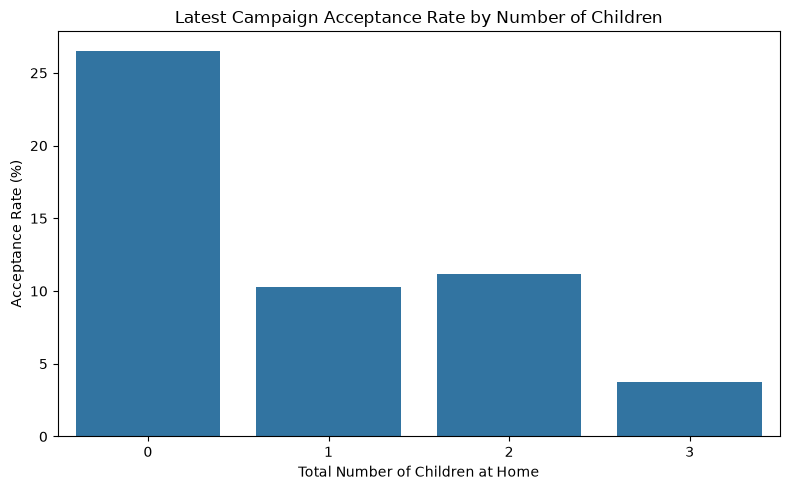

In [98]:
# Create a bar chart showing campaign acceptance rates by total number of children
plt.figure(figsize=(8, 5))

sns.barplot(
    x=children_acceptance.index,
    y=children_acceptance.values
)

# Add chart title and axis labels
plt.title("Latest Campaign Acceptance Rate by Number of Children")
plt.xlabel("Total Number of Children at Home")
plt.ylabel("Acceptance Rate (%)")

# Display the chart
plt.tight_layout()
plt.show()

In [ ]:
"Customers without children at home were considerably more responsive to the latest marketing campaign. "
"Although customers with one child represented the largest customer group, their acceptance rate was much lower. "
"Customers with three children showed the lowest response rate."

In [99]:
# Compare the latest campaign acceptance rate by marital status and total number of children
household_marital_acceptance = df_clean.pivot_table(
    index="Marital_Status",
    columns="Total_Children",
    values="Response",
    aggfunc="mean"
) * 100

# Display acceptance rates rounded to two decimal places
print(household_marital_acceptance.round(2))

Total_Children      0      1      2     3
Marital_Status                           
Divorced        44.83  10.92  18.37  0.00
Married         18.26   9.13   8.93  0.00
Single          38.92  13.00  15.07  6.25
Together        16.34   8.72   7.14  6.67
Unknown         50.00  33.33  50.00   NaN
Widow           37.04  18.18  17.65   NaN


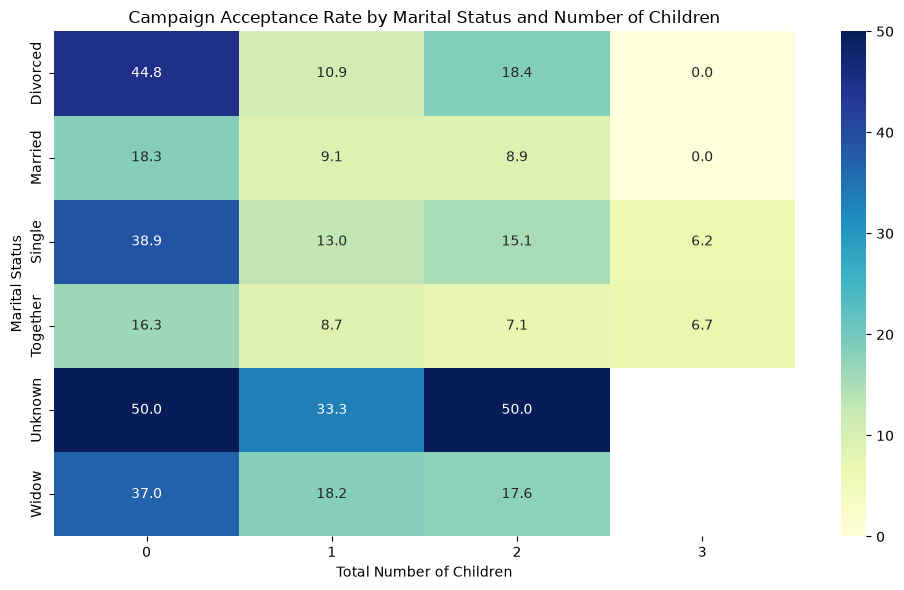

In [100]:
# Create a heatmap to compare campaign acceptance rates
# across marital status and household size
plt.figure(figsize=(10, 6))

sns.heatmap(
    household_marital_acceptance,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

# Add chart title and axis labels
plt.title("Campaign Acceptance Rate by Marital Status and Number of Children")
plt.xlabel("Total Number of Children")
plt.ylabel("Marital Status")

# Display the chart
plt.tight_layout()
plt.show()

In [ ]:
#Divorced customers without children: 44.8% acceptance rate.

#Single customers without children: 38.9%.

#Widowed customers without children: 37.0%.

#Married customers: acceptance rates are lower, particularly among those with one or two children.

#Customers with unknown marital status: rates are high, but we should be careful because this group may contain very few customers.